# Day 091 | Retaining Wall Design Optimization

**Author:** Ripon Chandra Malo

## Capstone Project: ML-Based Surrogate Optimization for Retaining Walls

Designing a gravity retaining wall involves balancing safety (factor of safety against sliding and overturning) with economy (minimizing concrete volume and cost). Traditional design involves iterative trial-and-error or parametric studies.

In this project, we use ML as a surrogate model to rapidly evaluate retaining wall performance, then optimize the geometry for minimum cost while satisfying stability constraints.

**Objectives:**
- Generate synthetic retaining wall design data (150 rows)
- Train surrogate ML model predicting FoS from geometry and soil
- Optimize wall geometry for minimum cost with FoS constraints
- Visualize the Pareto front and optimal designs

In [1]:
# ───── Part 1: Imports and Setup ─────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from scipy.optimize import minimize, differential_evolution
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print('All libraries loaded successfully.')

All libraries loaded successfully.


## Part 2: Retaining Wall Mechanics

For a cantilever retaining wall, we compute:
- **Active earth pressure** using Rankine theory: Ka = tan^2(45 - phi/2)
- **Factor of Safety against sliding:** FoS_slide = (W * tan(delta) + Pp) / Pa_h
- **Factor of Safety against overturning:** FoS_ot = M_resist / M_overturn
- **Cost** proportional to concrete volume + steel reinforcement estimate

Design variables: wall height (H), base width (B), stem thickness (t_stem), toe length (t_toe), heel length (t_heel)

In [2]:
# ───── Part 2: Retaining Wall Analysis Functions ─────
def analyze_retaining_wall(H, B, t_stem, t_base, toe_len, phi, gamma_soil,
                            gamma_concrete=24.0, delta_ratio=0.67, surcharge=0):
    """
    Analyze a cantilever retaining wall.

    Parameters:
    H: total wall height (m)
    B: base width (m)
    t_stem: stem thickness at base (m)
    t_base: base slab thickness (m)
    toe_len: toe length (m)
    phi: soil friction angle (degrees)
    gamma_soil: unit weight of backfill (kN/m3)
    """
    phi_rad = np.radians(phi)
    Ka = np.tan(np.radians(45 - phi / 2))**2
    Kp = np.tan(np.radians(45 + phi / 2))**2
    delta = delta_ratio * phi_rad  # Base friction angle

    # Heights
    H_stem = H - t_base
    heel_len = B - toe_len - t_stem

    # Active earth pressure
    Pa = 0.5 * Ka * gamma_soil * H**2 + Ka * surcharge * H
    Pa_h = Pa  # Horizontal component (vertical face)
    arm_Pa = H / 3  # Moment arm from base

    # Passive earth pressure (toe side, depth = t_base)
    Pp = 0.5 * Kp * gamma_soil * t_base**2

    # Weights and moments about toe
    # 1. Stem
    W_stem = gamma_concrete * t_stem * H_stem
    x_stem = toe_len + t_stem / 2

    # 2. Base slab
    W_base = gamma_concrete * B * t_base
    x_base = B / 2

    # 3. Soil on heel
    W_soil_heel = gamma_soil * heel_len * H_stem
    x_soil_heel = toe_len + t_stem + heel_len / 2

    # 4. Surcharge on heel
    W_surcharge = surcharge * heel_len
    x_surcharge = x_soil_heel

    # Total weight and resisting moment
    W_total = W_stem + W_base + W_soil_heel + W_surcharge
    M_resist = (W_stem * x_stem + W_base * x_base +
                W_soil_heel * x_soil_heel + W_surcharge * x_surcharge)

    # Overturning moment
    M_overturn = Pa_h * arm_Pa

    # Factors of Safety
    FoS_sliding = (W_total * np.tan(delta) + Pp) / max(Pa_h, 0.001)
    FoS_overturning = M_resist / max(M_overturn, 0.001)

    # Concrete volume per unit length (m3/m)
    V_concrete = t_stem * H_stem + B * t_base

    # Simplified cost (concrete + reinforcement estimate)
    cost = V_concrete * 150 + V_concrete * 0.02 * 8000  # concrete + steel

    return {
        'FoS_sliding': FoS_sliding,
        'FoS_overturning': FoS_overturning,
        'FoS_min': min(FoS_sliding, FoS_overturning),
        'V_concrete_m3': V_concrete,
        'cost_per_m': cost,
        'W_total_kN': W_total
    }

# Quick test
test_result = analyze_retaining_wall(5, 3.5, 0.4, 0.5, 1.0, 30, 18)
print('Test wall analysis:')
for k, v in test_result.items():
    print(f'  {k}: {v:.3f}')

Test wall analysis:
  FoS_sliding: 1.336
  FoS_overturning: 4.337
  FoS_min: 1.336
  V_concrete_m3: 3.550
  cost_per_m: 1100.500
  W_total_kN: 255.300


In [3]:
# ───── Part 3: Generate Synthetic Design Dataset ─────
n_samples = 150

# Design variables
H_vals = np.random.uniform(3.0, 10.0, n_samples)        # Wall height (m)
B_vals = np.random.uniform(1.5, 7.0, n_samples)         # Base width (m)
t_stem_vals = np.random.uniform(0.25, 0.8, n_samples)   # Stem thickness (m)
t_base_vals = np.random.uniform(0.3, 1.0, n_samples)    # Base thickness (m)
toe_vals = np.random.uniform(0.3, 2.5, n_samples)       # Toe length (m)

# Soil parameters
phi_vals = np.random.uniform(25, 40, n_samples)         # Friction angle (deg)
gamma_vals = np.random.uniform(16, 20, n_samples)       # Unit weight (kN/m3)
surcharge_vals = np.random.uniform(0, 20, n_samples)    # Surcharge (kPa)

# Ensure B > toe + t_stem (geometric feasibility)
for i in range(n_samples):
    B_vals[i] = max(B_vals[i], toe_vals[i] + t_stem_vals[i] + 0.5)

# Analyze all designs
records = []
for i in range(n_samples):
    result = analyze_retaining_wall(
        H_vals[i], B_vals[i], t_stem_vals[i], t_base_vals[i],
        toe_vals[i], phi_vals[i], gamma_vals[i], surcharge=surcharge_vals[i]
    )
    records.append({
        'H_m': round(H_vals[i], 2),
        'B_m': round(B_vals[i], 2),
        't_stem_m': round(t_stem_vals[i], 3),
        't_base_m': round(t_base_vals[i], 3),
        'toe_m': round(toe_vals[i], 2),
        'phi_deg': round(phi_vals[i], 1),
        'gamma_kNm3': round(gamma_vals[i], 2),
        'surcharge_kPa': round(surcharge_vals[i], 1),
        'B_over_H': round(B_vals[i] / H_vals[i], 3),
        **{k: round(v, 4) for k, v in result.items()}
    })

df = pd.DataFrame(records)
df.to_csv('retaining_wall_data.csv', index=False)
print(f'Dataset shape: {df.shape}')
print(f'\nFoS_sliding range: {df["FoS_sliding"].min():.2f} - {df["FoS_sliding"].max():.2f}')
print(f'FoS_overturning range: {df["FoS_overturning"].min():.2f} - {df["FoS_overturning"].max():.2f}')
print(f'Cost range: {df["cost_per_m"].min():.0f} - {df["cost_per_m"].max():.0f} per m')
df.head()

Dataset shape: (150, 15)

FoS_sliding range: 0.31 - 5.58
FoS_overturning range: 0.28 - 38.63
Cost range: 676 - 3354 per m


,H_m,B_m,t_stem_m,t_base_m,toe_m,phi_deg,gamma_kNm3,surcharge_kPa,B_over_H,FoS_sliding,FoS_overturning,FoS_min,V_concrete_m3,cost_per_m,W_total_kN
0,5.62,6.50,0.278,0.844,0.67,26.8,16.83,17.5,1.155,1.7687,9.5592,1.7687,6.8124,2111.8568,706.4546
1,9.66,2.82,0.542,0.691,0.91,39.1,16.11,10.6,0.292,1.0416,1.0535,1.0416,6.8074,2110.2857,374.4962
2,8.12,2.30,0.547,0.597,0.69,34.4,16.73,18.8,0.283,0.6750,0.7623,0.6750,5.4911,1702.2284,285.1637
3,7.19,4.19,0.601,0.934,0.50,30.0,18.33,16.0,0.583,1.2223,2.8478,1.2223,7.6746,2379.1145,588.7610
4,4.09,6.92,0.649,0.378,0.57,27.1,17.69,20.0,1.691,2.3627,19.2440,2.3627,5.0269,1558.3465,609.3848


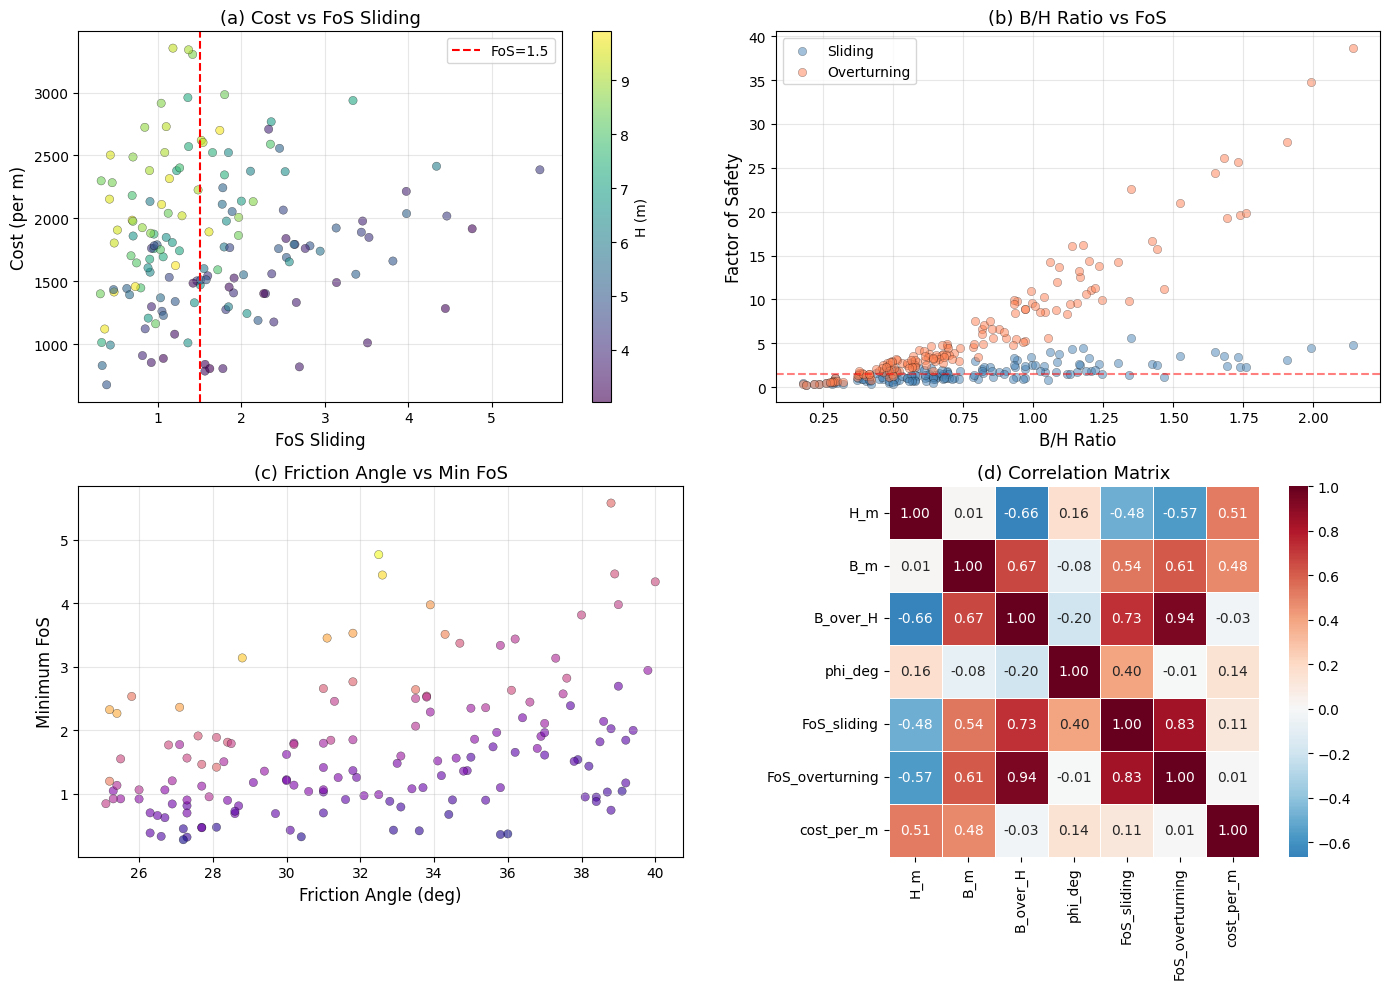

In [4]:
# ───── Part 4: Exploratory Visualization ─────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Cost vs FoS_sliding
sc1 = axes[0, 0].scatter(df['FoS_sliding'], df['cost_per_m'], c=df['H_m'],
                         cmap='viridis', alpha=0.6, edgecolors='k', linewidth=0.3)
plt.colorbar(sc1, ax=axes[0, 0], label='H (m)')
axes[0, 0].axvline(x=1.5, color='red', linestyle='--', label='FoS=1.5')
axes[0, 0].set_xlabel('FoS Sliding', fontsize=12)
axes[0, 0].set_ylabel('Cost (per m)', fontsize=12)
axes[0, 0].set_title('(a) Cost vs FoS Sliding', fontsize=13)
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# (b) B/H ratio vs FoS
axes[0, 1].scatter(df['B_over_H'], df['FoS_sliding'], alpha=0.5, c='steelblue',
                   label='Sliding', edgecolors='k', linewidth=0.3)
axes[0, 1].scatter(df['B_over_H'], df['FoS_overturning'], alpha=0.5, c='coral',
                   label='Overturning', edgecolors='k', linewidth=0.3)
axes[0, 1].axhline(y=1.5, color='red', linestyle='--', alpha=0.5)
axes[0, 1].set_xlabel('B/H Ratio', fontsize=12)
axes[0, 1].set_ylabel('Factor of Safety', fontsize=12)
axes[0, 1].set_title('(b) B/H Ratio vs FoS', fontsize=13)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# (c) Friction angle vs FoS
axes[1, 0].scatter(df['phi_deg'], df['FoS_min'], c=df['B_over_H'], cmap='plasma',
                   alpha=0.6, edgecolors='k', linewidth=0.3)
axes[1, 0].set_xlabel('Friction Angle (deg)', fontsize=12)
axes[1, 0].set_ylabel('Minimum FoS', fontsize=12)
axes[1, 0].set_title('(c) Friction Angle vs Min FoS', fontsize=13)
axes[1, 0].grid(True, alpha=0.3)

# (d) Correlation
corr_cols = ['H_m', 'B_m', 'B_over_H', 'phi_deg', 'FoS_sliding', 'FoS_overturning', 'cost_per_m']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=axes[1, 1], square=True, linewidths=0.5)
axes[1, 1].set_title('(d) Correlation Matrix', fontsize=13)

plt.tight_layout()
plt.savefig('eda_retaining_wall.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# ───── Part 5: Train Surrogate Models ─────
features = ['H_m', 'B_m', 't_stem_m', 't_base_m', 'toe_m',
            'phi_deg', 'gamma_kNm3', 'surcharge_kPa']

# Train separate models for sliding FoS, overturning FoS, and cost
X = df[features].values

targets_info = [
    ('FoS_sliding', 'FoS Sliding'),
    ('FoS_overturning', 'FoS Overturning'),
    ('cost_per_m', 'Cost per m')
]

surrogate_models = {}

for target_col, target_name in targets_info:
    y_target = df[target_col].values
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_target, test_size=0.2, random_state=42)

    model = GradientBoostingRegressor(
        n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    surrogate_models[target_col] = model
    print(f'{target_name}: R2 = {r2:.4f}, RMSE = {rmse:.4f}')

FoS Sliding: R2 = 0.7404, RMSE = 0.4203
FoS Overturning: R2 = 0.8734, RMSE = 1.7697


Cost per m: R2 = 0.7252, RMSE = 290.4793


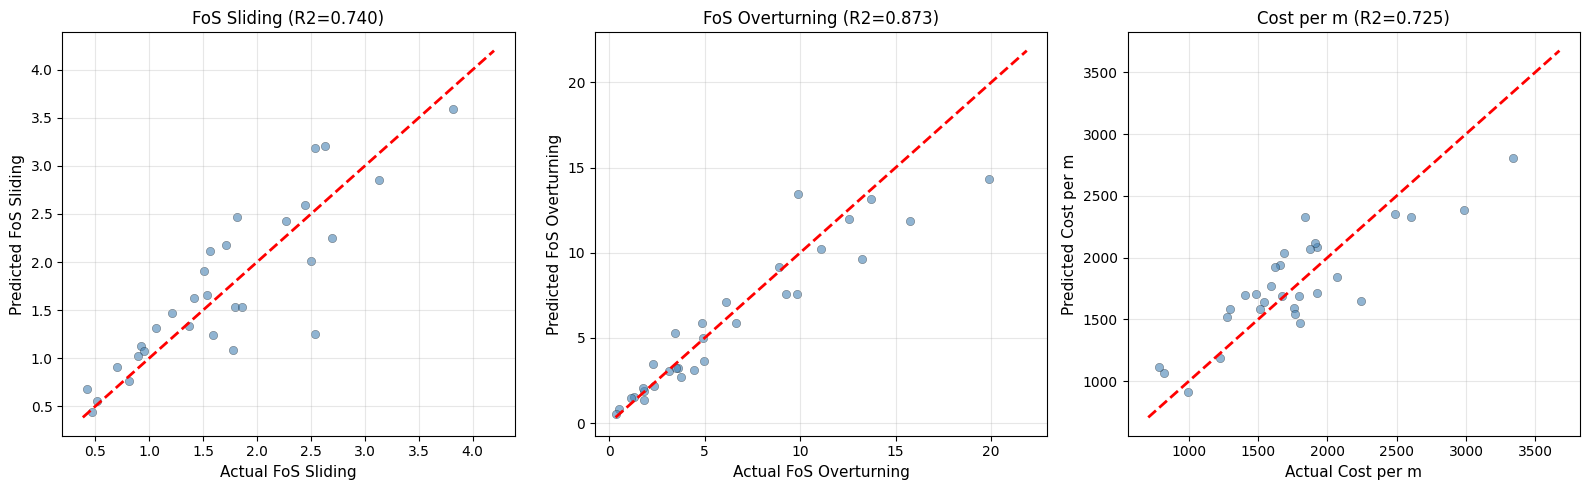

In [6]:
# ───── Part 6: Surrogate Model Validation ─────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, (target_col, target_name) in enumerate(targets_info):
    y_target = df[target_col].values
    _, X_test, _, y_test = train_test_split(X, y_target, test_size=0.2, random_state=42)
    y_pred = surrogate_models[target_col].predict(X_test)

    vmin = min(y_test.min(), y_pred.min()) * 0.9
    vmax = max(y_test.max(), y_pred.max()) * 1.1
    axes[idx].scatter(y_test, y_pred, alpha=0.6, c='steelblue', edgecolors='k', linewidth=0.3)
    axes[idx].plot([vmin, vmax], [vmin, vmax], 'r--', linewidth=2)
    axes[idx].set_xlabel(f'Actual {target_name}', fontsize=11)
    axes[idx].set_ylabel(f'Predicted {target_name}', fontsize=11)
    r2 = r2_score(y_test, y_pred)
    axes[idx].set_title(f'{target_name} (R2={r2:.3f})', fontsize=12)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('surrogate_validation.png', dpi=150, bbox_inches='tight')
plt.show()

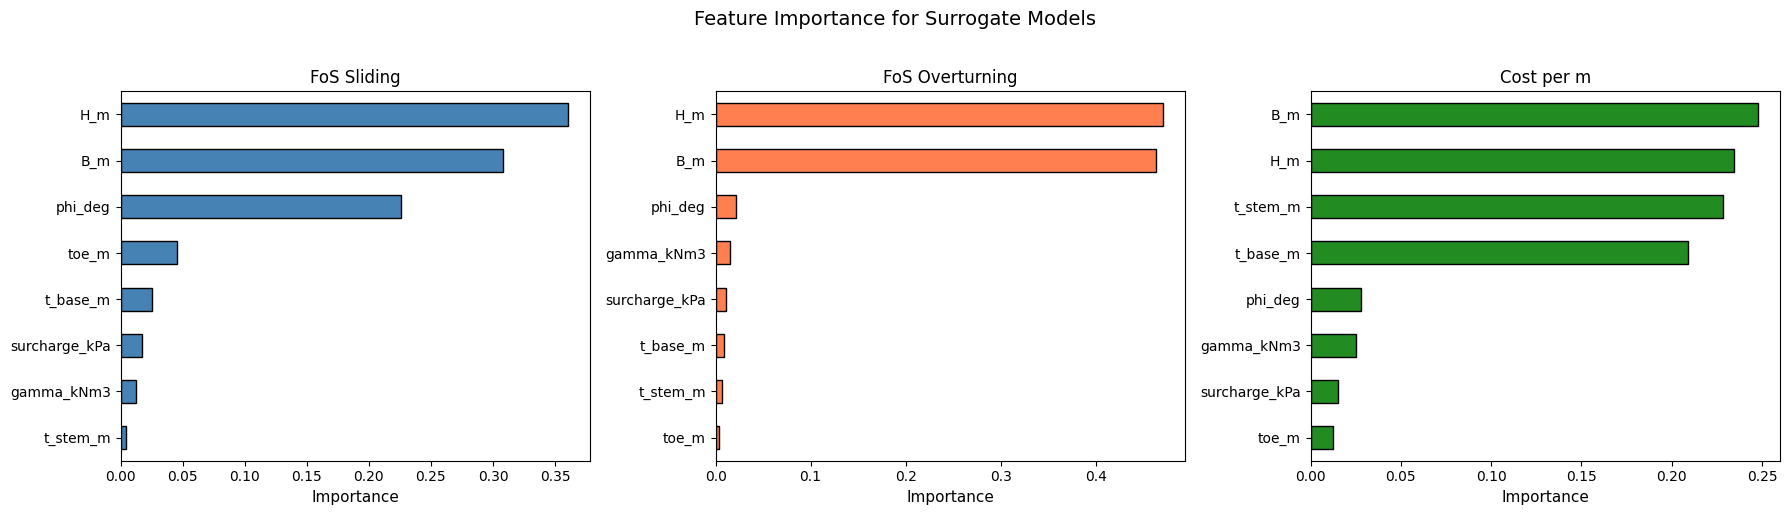

In [7]:
# ───── Part 7: Feature Importance for Surrogates ─────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors_fi = ['steelblue', 'coral', 'forestgreen']

for idx, (target_col, target_name) in enumerate(targets_info):
    imp = pd.Series(surrogate_models[target_col].feature_importances_,
                    index=features).sort_values()
    imp.plot(kind='barh', ax=axes[idx], color=colors_fi[idx], edgecolor='black')
    axes[idx].set_title(f'{target_name}', fontsize=12)
    axes[idx].set_xlabel('Importance', fontsize=11)

plt.suptitle('Feature Importance for Surrogate Models', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 8: Design Optimization

We optimize the retaining wall geometry to minimize cost while satisfying:
- FoS_sliding >= 1.5
- FoS_overturning >= 2.0

We use differential evolution (a global optimization algorithm) with the ML surrogate as the objective/constraint evaluator.

In [8]:
# ───── Part 8: Optimization with Surrogate ─────
def objective(x, phi=30, gamma=18, surcharge=10):
    """Objective: minimize cost with penalty for FoS violation."""
    H, B, t_stem, t_base, toe = x

    # Feasibility check
    if B < toe + t_stem + 0.3:
        return 1e6

    features_val = np.array([[H, B, t_stem, t_base, toe, phi, gamma, surcharge]])

    cost = surrogate_models['cost_per_m'].predict(features_val)[0]
    fos_slide = surrogate_models['FoS_sliding'].predict(features_val)[0]
    fos_ot = surrogate_models['FoS_overturning'].predict(features_val)[0]

    # Penalty for constraint violation
    penalty = 0
    if fos_slide < 1.5:
        penalty += 5000 * (1.5 - fos_slide)**2
    if fos_ot < 2.0:
        penalty += 5000 * (2.0 - fos_ot)**2

    return cost + penalty

# Optimization bounds
bounds = [
    (3.0, 10.0),   # H
    (1.5, 7.0),    # B
    (0.25, 0.8),   # t_stem
    (0.3, 1.0),    # t_base
    (0.3, 2.5)     # toe
]

# Run optimization for different wall heights
heights_to_optimize = [4.0, 5.0, 6.0, 7.0, 8.0]
optimal_designs = []

for H_target in heights_to_optimize:
    bounds_fixed = [
        (H_target, H_target),  # Fix height
        (1.5, 7.0),
        (0.25, 0.8),
        (0.3, 1.0),
        (0.3, 2.5)
    ]

    result = differential_evolution(objective, bounds_fixed, seed=42,
                                   maxiter=200, tol=1e-6,
                                   args=(30, 18, 10))

    H_opt, B_opt, ts_opt, tb_opt, toe_opt = result.x
    feats = np.array([[H_opt, B_opt, ts_opt, tb_opt, toe_opt, 30, 18, 10]])

    fos_s = surrogate_models['FoS_sliding'].predict(feats)[0]
    fos_o = surrogate_models['FoS_overturning'].predict(feats)[0]
    cost = surrogate_models['cost_per_m'].predict(feats)[0]

    optimal_designs.append({
        'H_m': round(H_opt, 2), 'B_m': round(B_opt, 2),
        't_stem_m': round(ts_opt, 3), 't_base_m': round(tb_opt, 3),
        'toe_m': round(toe_opt, 2),
        'B_over_H': round(B_opt / H_opt, 3),
        'FoS_sliding': round(fos_s, 3),
        'FoS_overturning': round(fos_o, 3),
        'cost_per_m': round(cost, 0)
    })
    print(f'H={H_opt:.1f}m: B={B_opt:.2f}m, B/H={B_opt/H_opt:.2f}, '
          f'FoS_s={fos_s:.2f}, FoS_ot={fos_o:.2f}, Cost={cost:.0f}')

opt_df = pd.DataFrame(optimal_designs)
print('\n=== Optimal Designs ===')
print(opt_df.to_string(index=False))

H=4.0m: B=2.36m, B/H=0.59, FoS_s=1.50, FoS_ot=6.74, Cost=803


H=5.0m: B=4.09m, B/H=0.82, FoS_s=1.48, FoS_ot=6.72, Cost=813


H=6.0m: B=4.09m, B/H=0.68, FoS_s=1.29, FoS_ot=3.55, Cost=821


H=7.0m: B=5.50m, B/H=0.79, FoS_s=1.37, FoS_ot=7.25, Cost=1164


H=8.0m: B=5.49m, B/H=0.69, FoS_s=1.19, FoS_ot=4.37, Cost=1165

=== Optimal Designs ===
 H_m  B_m  t_stem_m  t_base_m  toe_m  B_over_H  FoS_sliding  FoS_overturning  cost_per_m
 4.0 2.36     0.298     0.330   1.05     0.590        1.502            6.738       803.0
 5.0 4.09     0.283     0.335   0.90     0.818        1.484            6.716       813.0
 6.0 4.09     0.300     0.339   0.49     0.681        1.294            3.550       821.0
 7.0 5.50     0.284     0.331   1.20     0.785        1.367            7.249      1164.0
 8.0 5.49     0.273     0.340   1.20     0.686        1.188            4.368      1165.0


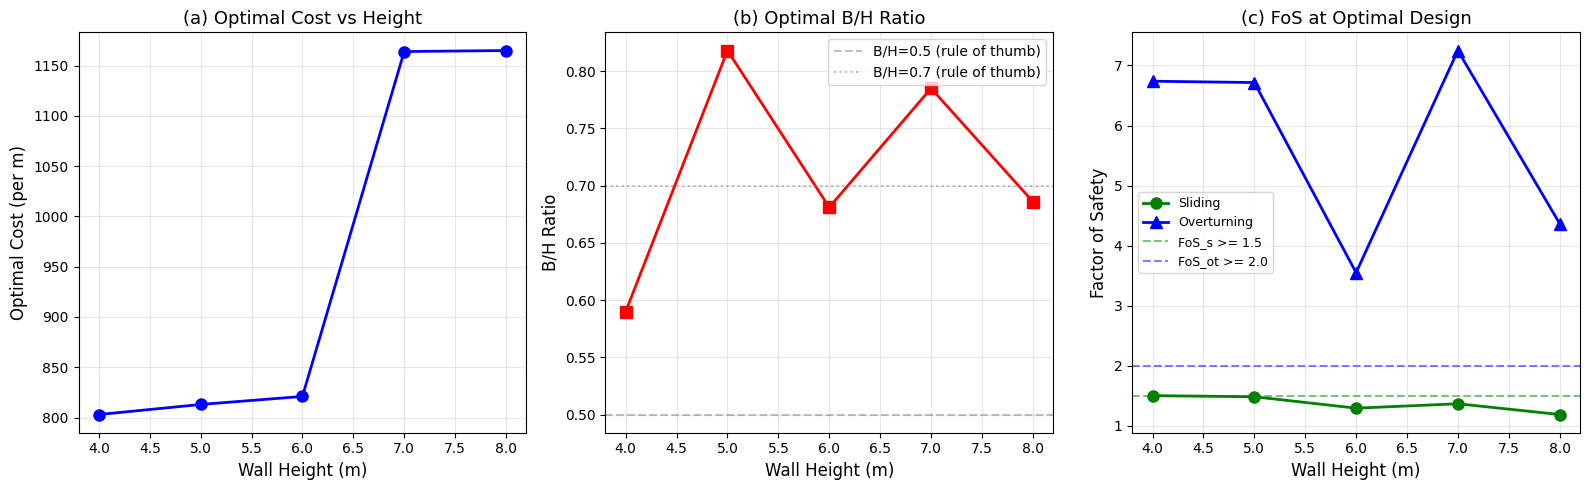

In [9]:
# ───── Part 9: Visualize Optimal Designs ─────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (a) Cost vs Height for optimal designs
axes[0].plot(opt_df['H_m'], opt_df['cost_per_m'], 'bo-', markersize=8, linewidth=2)
axes[0].set_xlabel('Wall Height (m)', fontsize=12)
axes[0].set_ylabel('Optimal Cost (per m)', fontsize=12)
axes[0].set_title('(a) Optimal Cost vs Height', fontsize=13)
axes[0].grid(True, alpha=0.3)

# (b) B/H ratio vs Height
axes[1].plot(opt_df['H_m'], opt_df['B_over_H'], 'rs-', markersize=8, linewidth=2)
axes[1].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='B/H=0.5 (rule of thumb)')
axes[1].axhline(y=0.7, color='gray', linestyle=':', alpha=0.5, label='B/H=0.7 (rule of thumb)')
axes[1].set_xlabel('Wall Height (m)', fontsize=12)
axes[1].set_ylabel('B/H Ratio', fontsize=12)
axes[1].set_title('(b) Optimal B/H Ratio', fontsize=13)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# (c) FoS values
axes[2].plot(opt_df['H_m'], opt_df['FoS_sliding'], 'go-', markersize=8,
             linewidth=2, label='Sliding')
axes[2].plot(opt_df['H_m'], opt_df['FoS_overturning'], 'b^-', markersize=8,
             linewidth=2, label='Overturning')
axes[2].axhline(y=1.5, color='green', linestyle='--', alpha=0.5, label='FoS_s >= 1.5')
axes[2].axhline(y=2.0, color='blue', linestyle='--', alpha=0.5, label='FoS_ot >= 2.0')
axes[2].set_xlabel('Wall Height (m)', fontsize=12)
axes[2].set_ylabel('Factor of Safety', fontsize=12)
axes[2].set_title('(c) FoS at Optimal Design', fontsize=13)
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('optimal_designs.png', dpi=150, bbox_inches='tight')
plt.show()

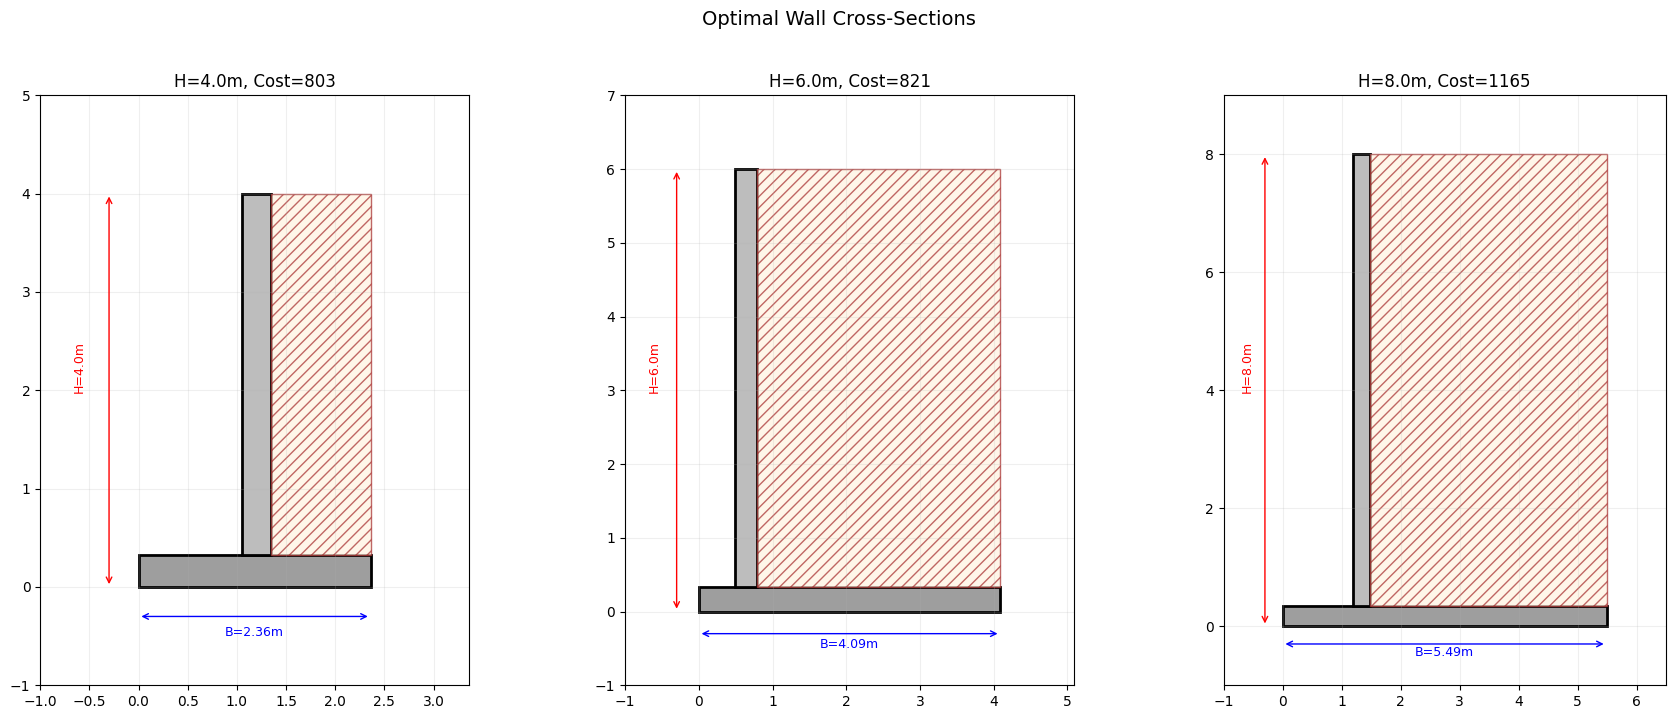

In [10]:
# ───── Part 10: Visualize a Wall Cross-Section ─────
def plot_wall(H, B, t_stem, t_base, toe, ax, title=''):
    """Draw cross-section of retaining wall."""
    heel = B - toe - t_stem
    H_stem = H - t_base

    # Base slab
    base = plt.Polygon([(0, 0), (B, 0), (B, t_base), (0, t_base)],
                       facecolor='#9E9E9E', edgecolor='black', linewidth=2)
    ax.add_patch(base)

    # Stem
    stem = plt.Polygon([(toe, t_base), (toe + t_stem, t_base),
                        (toe + t_stem, H), (toe, H)],
                       facecolor='#BDBDBD', edgecolor='black', linewidth=2)
    ax.add_patch(stem)

    # Backfill (hatching)
    backfill = plt.Polygon([(toe + t_stem, t_base), (B, t_base),
                            (B, H), (toe + t_stem, H)],
                           facecolor='#FFF3E0', edgecolor='brown',
                           linewidth=1, hatch='///', alpha=0.7)
    ax.add_patch(backfill)

    # Dimensions
    ax.annotate('', xy=(0, -0.3), xytext=(B, -0.3),
                arrowprops=dict(arrowstyle='<->', color='blue'))
    ax.text(B/2, -0.5, f'B={B:.2f}m', ha='center', fontsize=9, color='blue')

    ax.annotate('', xy=(-0.3, 0), xytext=(-0.3, H),
                arrowprops=dict(arrowstyle='<->', color='red'))
    ax.text(-0.6, H/2, f'H={H:.1f}m', ha='center', fontsize=9, color='red', rotation=90)

    ax.set_xlim(-1, B + 1)
    ax.set_ylim(-1, H + 1)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.2)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for idx, i in enumerate([0, 2, 4]):
    d = optimal_designs[i]
    plot_wall(d['H_m'], d['B_m'], d['t_stem_m'], d['t_base_m'], d['toe_m'],
             axes[idx], title=f"H={d['H_m']}m, Cost={d['cost_per_m']:.0f}")

plt.suptitle('Optimal Wall Cross-Sections', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('wall_crosssections.png', dpi=150, bbox_inches='tight')
plt.show()

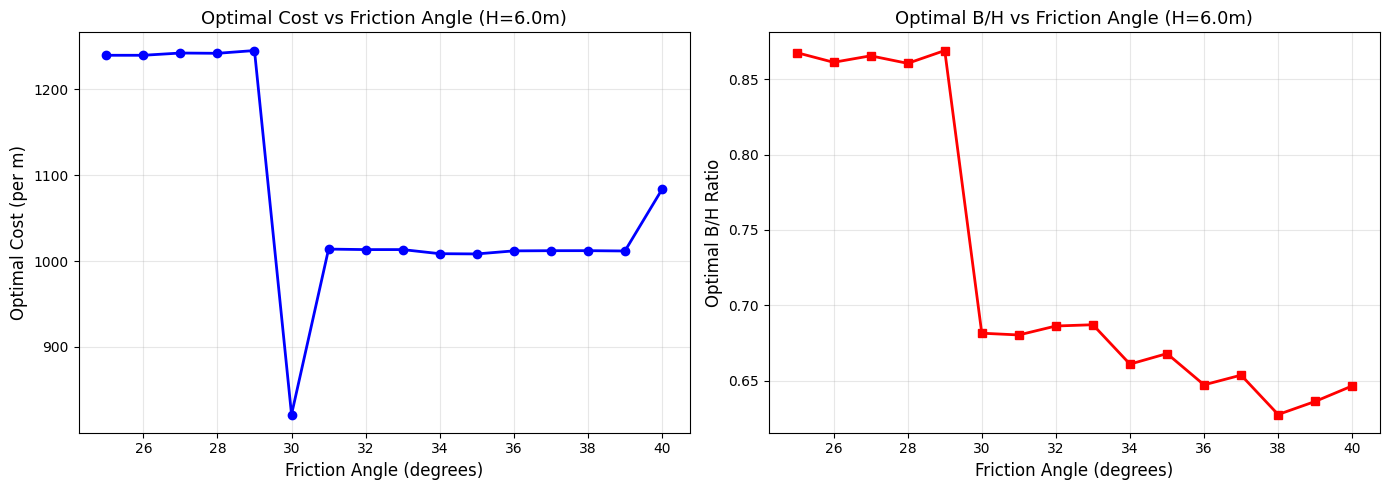

In [11]:
# ───── Part 11: Parametric Study - Effect of Friction Angle ─────
phi_range = np.arange(25, 41, 1)
H_fixed = 6.0
opt_costs = []
opt_B_over_H = []

for phi_val in phi_range:
    bounds_phi = [
        (H_fixed, H_fixed),
        (1.5, 7.0),
        (0.25, 0.8),
        (0.3, 1.0),
        (0.3, 2.5)
    ]
    result = differential_evolution(objective, bounds_phi, seed=42,
                                   maxiter=100, args=(phi_val, 18, 10))
    _, B_opt, _, _, _ = result.x
    feats = np.array([[H_fixed, B_opt, result.x[2], result.x[3], result.x[4],
                       phi_val, 18, 10]])
    cost = surrogate_models['cost_per_m'].predict(feats)[0]
    opt_costs.append(cost)
    opt_B_over_H.append(B_opt / H_fixed)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(phi_range, opt_costs, 'bo-', markersize=6, linewidth=2)
ax1.set_xlabel('Friction Angle (degrees)', fontsize=12)
ax1.set_ylabel('Optimal Cost (per m)', fontsize=12)
ax1.set_title(f'Optimal Cost vs Friction Angle (H={H_fixed}m)', fontsize=13)
ax1.grid(True, alpha=0.3)

ax2.plot(phi_range, opt_B_over_H, 'rs-', markersize=6, linewidth=2)
ax2.set_xlabel('Friction Angle (degrees)', fontsize=12)
ax2.set_ylabel('Optimal B/H Ratio', fontsize=12)
ax2.set_title(f'Optimal B/H vs Friction Angle (H={H_fixed}m)', fontsize=13)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('parametric_phi.png', dpi=150, bbox_inches='tight')
plt.show()

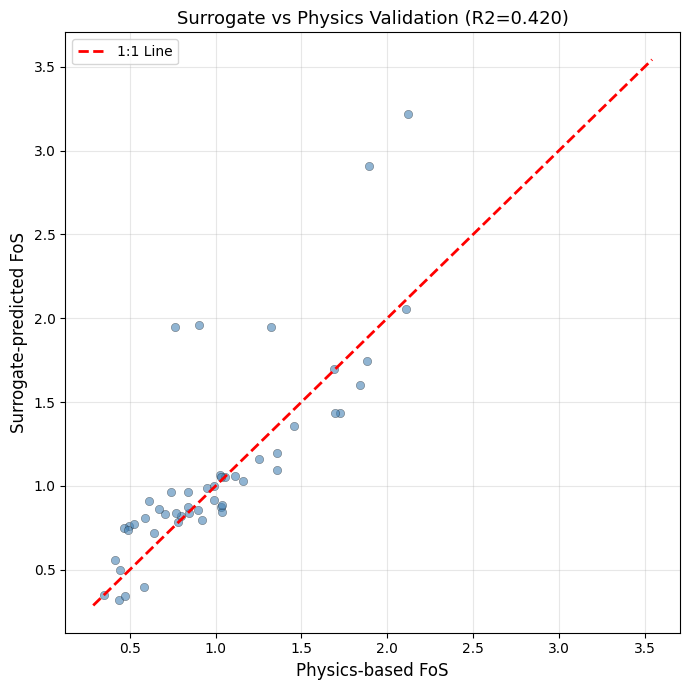

In [12]:
# ───── Part 12: Surrogate vs Physics Validation ─────
# Compare surrogate predictions with physics-based calculations
n_val = 50
val_H = np.random.uniform(3.5, 9, n_val)
val_B = np.random.uniform(2, 6, n_val)
val_ts = np.random.uniform(0.3, 0.7, n_val)
val_tb = np.random.uniform(0.3, 0.8, n_val)
val_toe = np.random.uniform(0.4, 2.0, n_val)

for i in range(n_val):
    val_B[i] = max(val_B[i], val_toe[i] + val_ts[i] + 0.5)

fos_physics = []
fos_surrogate = []

for i in range(n_val):
    res = analyze_retaining_wall(val_H[i], val_B[i], val_ts[i], val_tb[i],
                                 val_toe[i], 30, 18, surcharge=10)
    fos_physics.append(res['FoS_sliding'])

    feats = np.array([[val_H[i], val_B[i], val_ts[i], val_tb[i], val_toe[i], 30, 18, 10]])
    fos_surrogate.append(surrogate_models['FoS_sliding'].predict(feats)[0])

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(fos_physics, fos_surrogate, alpha=0.6, c='steelblue',
           edgecolors='k', linewidth=0.3)
vmin = min(min(fos_physics), min(fos_surrogate)) * 0.9
vmax = max(max(fos_physics), max(fos_surrogate)) * 1.1
ax.plot([vmin, vmax], [vmin, vmax], 'r--', linewidth=2, label='1:1 Line')
r2 = r2_score(fos_physics, fos_surrogate)
ax.set_xlabel('Physics-based FoS', fontsize=12)
ax.set_ylabel('Surrogate-predicted FoS', fontsize=12)
ax.set_title(f'Surrogate vs Physics Validation (R2={r2:.3f})', fontsize=13)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('surrogate_validation_physics.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Takeaways

1. **ML surrogate models accurately reproduce physics-based retaining wall analysis**, enabling rapid design evaluation for optimization.

2. **Base width and wall height are the most influential parameters** for both stability and cost, with the optimal B/H ratio typically falling within the 0.5-0.7 range recommended by practice.

3. **Higher soil friction angles allow more economical designs** with smaller base widths, demonstrating the economic value of accurate site characterization.

4. **Differential evolution with ML surrogates finds optimal designs efficiently**, avoiding the need for thousands of physics evaluations.

5. **The optimization naturally produces designs where constraints are active** -- the optimal FoS values are close to the minimum required, avoiding over-conservative (costly) designs.

## Next Steps

- Incorporate seismic loading (Mononobe-Okabe method)
- Add bearing capacity check as a constraint
- Multi-objective optimization (Pareto front of cost vs reliability)
- Use Bayesian optimization for sample-efficient surrogate training
- Extend to sheet pile and anchored wall systems